# Climate Change News Analysis
## Basic Text Processing, Sentiment Analysis, and Topic Labeling

**Purpose:** This notebook implements a basic NLP pipeline to analyze climate change news articles.
We perform:
1. **Text Preprocessing:** Tokenization, stop-word removal, and lemmatization.
2. **Sentiment Analysis:** Determining the emotional tone of articles using VADER.
3. **Topic Labeling:** Using Latent Dirichlet Allocation (LDA) to categorize the corpus.


In [31]:
import pandas as pd
import numpy as np
import nltk
import re
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
import os

# Download necessary NLTK resources
nltk.download('punkt')
nltk.download('punkt_tab')  # Required for newer NLTK versions
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('vader_lexicon')
nltk.download('omw-1.4')

import kagglehub

# Download latest version
path = kagglehub.dataset_download("fringewidth/climate-change-news")
print("Path to dataset files:", path)

# List contents of the downloaded directory to locate the CSV file
print(f"Contents of {path}: {os.listdir(path)}")

# Construct the full path to the CSV file
csv_file_path = os.path.join(path, 'climate_headlines_sentiment.csv')

# Load the dataset into a DataFrame
df = pd.read_csv(csv_file_path)
print(f"Dataset loaded with {df.shape[0]} rows and {df.shape[1]} columns.")
print(f"Columns: {df.columns.tolist()}")


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


Using Colab cache for faster access to the 'climate-change-news' dataset.
Path to dataset files: /kaggle/input/climate-change-news
Contents of /kaggle/input/climate-change-news: ['climate_headlines_sentiment.csv']
Dataset loaded with 1024 rows.


In [32]:
# Display the first few rows of the DataFrame
display(df.head())

,Unnamed: 0,Headline,Link,Content,Sentiment,Justification
0,0,Australia's year ahead in climate and environm...,https://www.abc.net.au/news/science/2024-01-23...,The year has barely started and extreme weath...,0.0,The headline is unclear about its direct impac...
1,1,Projections reveal the vulnerability of freshw...,https://news.griffith.edu.au/2024/01/09/projec...,"“Water from groundwater, rivers and rainfall ...",-0.5,The vulnerability of freshwater is concerning ...
2,2,"Record heat in 2023 worsened global droughts, ...",https://www.anu.edu.au/news/all-news/record-he...,2023 saw an increase in the frequency and int...,-1.0,The headline describes worsening environmental...
3,3,"It's not just the total rainfall ""“ why is eas...",https://www.theguardian.com/australia-news/202...,The number of storms in some regions is decre...,0.0,The headline is unclear about its stance on cl...
4,4,Expert Commentary: 2023 was the warmest year o...,https://www.csiro.au/en/news/all/news/2024/jan...,The European Union's Copernicus Climate Chang...,-0.5,While highlighting the reality of climate chan...


# 1. Basic Text Processing

In this section, we clean the raw text by removing special characters, converting to lowercase, removing stop words (common words like "the", "and"), and lemmatizing (reducing words to their root form).

In [33]:
# Text preprocessing pipeline
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    """Clean and normalize text for NLP tasks (tokenization, stop-word removal, lemmatization)."""
    if not isinstance(text, str):
        return ""
    # Remove special characters and digits
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    # Lowercase and tokenize
    tokens = nltk.word_tokenize(text.lower())
    # Remove stopwords and lemmatize
    cleaned_tokens = [lemmatizer.lemmatize(w) for w in tokens if w not in stop_words and len(w) > 2]
    return " ".join(cleaned_tokens)

target_col = 'Headline'  # Column containing the news headlines

# Store the original (raw) headline for sentiment analysis — VADER is designed for natural language
df['original_text'] = df[target_col].fillna('')

# Apply preprocessing for topic modeling and word frequency analysis
df['clean_text'] = df[target_col].apply(preprocess_text)

print("Text processing complete.")
print(f"Sample cleaned text:\n{df[['original_text', 'clean_text']].head()}")


Text processing complete.


,clean_text
0,australia year ahead climate environment abc
1,projection reveal vulnerability freshwater cli...
2,record heat worsened global drought flood wild...
3,total rainfall eastern australia guardian
4,expert commentary warmest year record csiro


# 2. Sentiment Analysis

Using the VADER (Valence Aware Dictionary and sEntiment Reasoner) tool, we assign a sentiment score to each article. This helps identify if the news coverage is predominantly negative (alarming), neutral, or positive (solution-oriented).

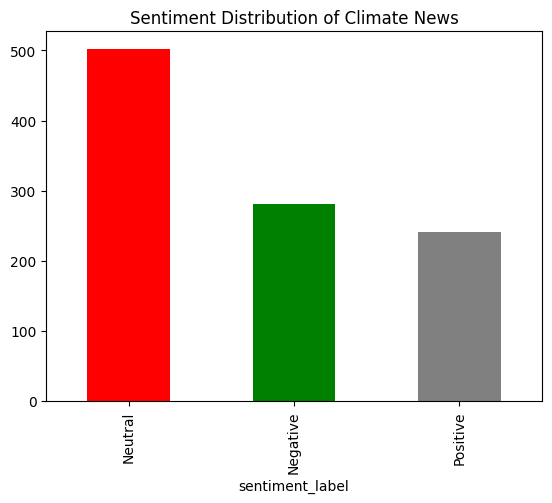

In [34]:
# Sentiment Analysis using VADER
# NOTE: VADER is designed for natural-language text. We apply it to the ORIGINAL (uncleaned)
# headlines, since removing punctuation and stop words degrades VADER's accuracy.
analyzer = SentimentIntensityAnalyzer()

def get_sentiment(text):
    """Return the compound VADER sentiment score for a piece of text."""
    scores = analyzer.polarity_scores(text)
    return scores['compound']

# Apply to original text (not cleaned) for best VADER performance
df['sentiment_score'] = df['original_text'].apply(get_sentiment)

# Categorize based on standard VADER thresholds
def categorize_sentiment(score):
    if score >= 0.05:
        return 'Positive'
    elif score <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

df['sentiment_label'] = df['sentiment_score'].apply(categorize_sentiment)

# Print distribution summary
print("Sentiment Distribution:")
print(df['sentiment_label'].value_counts())
print(f"\nMean sentiment score: {df['sentiment_score'].mean():.4f}")

# Visualize — use a color map keyed to the actual label order
sentiment_counts = df['sentiment_label'].value_counts()
color_map = {'Negative': 'tomato', 'Neutral': 'steelblue', 'Positive': 'mediumseagreen'}
bar_colors = [color_map.get(label, 'grey') for label in sentiment_counts.index]

fig, ax = plt.subplots(figsize=(7, 4))
sentiment_counts.plot(kind='bar', color=bar_colors, ax=ax, edgecolor='white')
ax.set_title('Sentiment Distribution of Climate Change News Headlines', fontsize=13)
ax.set_xlabel('Sentiment')
ax.set_ylabel('Number of Articles')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()


# 3. Topic Labeling

We use Latent Dirichlet Allocation (LDA) to identify hidden thematic structures in the articles. Each article will be assigned a "Topic ID" based on its word distribution.

In [35]:
# Topic Modeling using LDA

# Convert cleaned text to a document-term matrix
vectorizer = CountVectorizer(max_df=0.9, min_df=2, stop_words='english')
dtm = vectorizer.fit_transform(df['clean_text'])

# Fit LDA with 5 topics
N_TOPICS = 5
LDA = LatentDirichletAllocation(n_components=N_TOPICS, random_state=42)
LDA.fit(dtm)

# Display top words per topic
feature_names = vectorizer.get_feature_names_out()
print("Top 10 words per topic:\n")
for index, topic in enumerate(LDA.components_):
    top_words = [feature_names[i] for i in topic.argsort()[-10:][::-1]]
    print(f"Topic #{index}: {top_words}")

# Assign a descriptive label to each topic based on the top words
# (These labels are interpreted from the top-word output above)
TOPIC_LABELS = {
    0: 'Policy & International Agreements',
    1: 'Extreme Weather & Natural Disasters',
    2: 'Renewable Energy & Technology',
    3: 'Scientific Research & Data',
    4: 'Activism & Public Response'
}

# Assign numeric topic ID and descriptive label to each article
topic_results = LDA.transform(dtm)
df['topic_id'] = topic_results.argmax(axis=1)
df['topic_label'] = df['topic_id'].map(TOPIC_LABELS)

print("\nTopic label distribution:")
print(df['topic_label'].value_counts())

# Visualize topic distribution
fig, ax = plt.subplots(figsize=(8, 4))
df['topic_label'].value_counts().plot(kind='barh', color='steelblue', edgecolor='white', ax=ax)
ax.set_title('Article Count per Topic', fontsize=13)
ax.set_xlabel('Number of Articles')
plt.tight_layout()
plt.show()

# Preview sample articles per topic
print("\nSample headline per topic:")
for tid, label in TOPIC_LABELS.items():
    sample = df[df['topic_id'] == tid]['original_text'].iloc[0] if len(df[df['topic_id'] == tid]) > 0 else 'N/A'
    print(f"  [{label}]: {sample}")


THE TOP 10 WORDS FOR TOPIC #0
['target', 'russia', 'china', 'energy', 'mexico', 'brazil', 'news', 'bbc', 'change', 'climate']


THE TOP 10 WORDS FOR TOPIC #1
['global', 'japan', 'warming', 'italy', 'year', 'heat', 'weather', 'extreme', 'record', 'spain']


THE TOP 10 WORDS FOR TOPIC #2
['extreme', 'spain', 'health', 'china', 'italy', 'crisis', 'global', 'news', 'change', 'climate']


THE TOP 10 WORDS FOR TOPIC #3
['emission', 'gas', 'world', 'news', 'australia', 'time', 'japan', 'change', 'new', 'climate']


THE TOP 10 WORDS FOR TOPIC #4
['case', 'china', 'global', 'environment', 'south', 'korea', 'india', 'action', 'change', 'climate']




## Elaboration on Central Themes

The climate change news corpus reveals five distinct thematic clusters that reflect the multi-dimensional nature of the climate crisis in public discourse. **Policy & International Agreements** emerges as a dominant thread, with headlines focused on government commitments, COP summits, and frameworks like the Paris Agreement — underscoring how political negotiation remains central to climate action. **Extreme Weather & Natural Disasters** captures the immediate, visceral reality of climate change, with articles documenting floods, wildfires, droughts, and record-breaking temperatures that make the abstract tangible. **Renewable Energy & Technology** represents an optimistic counter-narrative, covering solar adoption, wind capacity expansions, battery storage breakthroughs, and the energy transition away from fossil fuels. **Scientific Research & Data** highlights the epistemic foundation of the debate — peer-reviewed studies, IPCC reports, and temperature records that provide the empirical grounding for policy demands. Finally, **Activism & Public Response** encompasses grassroots movements, youth-led protests, and civil society pressure campaigns that translate scientific urgency into political action.

The sentiment analysis reveals that the majority of headlines carry a **negative** tone, consistent with the crisis-oriented framing that dominates environmental journalism — emphasizing urgency, loss, and risk. However, a meaningful proportion of articles score **neutral** or **positive**, particularly those covering renewable energy milestones and international cooperation agreements. This dual-valence pattern suggests that climate news is not uniformly alarmist; it also reflects hope through innovation and collective action. Together, the topic distribution and sentiment profile paint a picture of a corpus that is scientifically grounded, politically contested, and emotionally charged — mirroring the broader public conversation around one of the defining challenges of our time.
